In [1]:
import sys
print(sys.version)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Basic libraries are working!")



3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Basic libraries are working!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving DailyDelhiClimateTrain.csv.zip to DailyDelhiClimateTrain.csv.zip


In [7]:

import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir("/content"))


Current folder: /content
Files available: ['.config', 'DailyDelhiClimateTrain.csv.zip', 'sample_data']


In [8]:

from google.colab import files

uploaded = files.upload()

print("Uploaded file names:", list(uploaded.keys()))


Saving DailyDelhiClimateTrain.csv.zip to DailyDelhiClimateTrain.csv (1).zip
Uploaded file names: ['DailyDelhiClimateTrain.csv (1).zip']


In [10]:

import zipfile
import os

zip_filename = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall("/content/climate_data")

print(os.listdir("/content/climate_data"))


['DailyDelhiClimateTrain.csv', 'DailyDelhiClimateTest.csv']


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/content/climate_data/DailyDelhiClimateTrain.csv"
)

print(df.head())
print(df.info())
print("Dataset shape:", df.shape)


         date   meantemp   humidity  wind_speed  meanpressure
0  2013-01-01  10.000000  84.500000    0.000000   1015.666667
1  2013-01-02   7.400000  92.000000    2.980000   1017.800000
2  2013-01-03   7.166667  87.000000    4.633333   1018.666667
3  2013-01-04   8.666667  71.333333    1.233333   1017.166667
4  2013-01-05   6.000000  86.833333    3.700000   1016.500000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1462 non-null   object 
 1   meantemp      1462 non-null   float64
 2   humidity      1462 non-null   float64
 3   wind_speed    1462 non-null   float64
 4   meanpressure  1462 non-null   float64
dtypes: float64(4), object(1)
memory usage: 57.2+ KB
None
Dataset shape: (1462, 5)


In [12]:

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")
df = df.drop_duplicates(subset="date")
df = df.set_index("date")

df = df.apply(pd.to_numeric, errors="coerce")

# Missing values: previous valid value-ஐ பயன்படுத்துதல்
df = df.ffill()

# ஆரம்பத்தில் missing values இருந்தால் அவற்றை நீக்குதல்
df = df.dropna()

print(df.head())
print("Total records:", len(df))
print("Missing values:")
print(df.isnull().sum())


             meantemp   humidity  wind_speed  meanpressure
date                                                      
2013-01-01  10.000000  84.500000    0.000000   1015.666667
2013-01-02   7.400000  92.000000    2.980000   1017.800000
2013-01-03   7.166667  87.000000    4.633333   1018.666667
2013-01-04   8.666667  71.333333    1.233333   1017.166667
2013-01-05   6.000000  86.833333    3.700000   1016.500000
Total records: 1462
Missing values:
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


In [13]:

target = "meantemp"

if target not in df.columns:
    raise ValueError("meantemp column not found!")

features = df.columns.tolist()

print("Input features:", features)
print("Target:", target)


Input features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
Target: meantemp


In [14]:

from sklearn.preprocessing import MinMaxScaler

split_idx = int(len(df) * 0.80)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(train_df[features])
target_scaler.fit(train_df[[target]])

X_scaled = feature_scaler.transform(df[features])
y_scaled = target_scaler.transform(
    df[[target]]
).ravel()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))


Training records: 1169
Testing records: 293


In [15]:

WINDOW = 30

X, y, target_indices = [], [], []

for i in range(WINDOW, len(df)):
    X.append(X_scaled[i-WINDOW:i])
    y.append(y_scaled[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (1139, 30, 4)
X_test shape: (293, 30, 4)


In [16]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(64, input_shape=(WINDOW, len(features))),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(64, input_shape=(WINDOW, len(features))),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0)

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred = target_scaler.inverse_transform(
    pred_scaled
).ravel()

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

print(f"LSTM MAE: {mae:.4f}")
print(f"LSTM RMSE: {rmse:.4f}")


LSTM MAE: 25.5726
LSTM RMSE: 26.1896


In [19]:

baseline_scaled = X_test[:, -1, features.index(target)]

baseline_pred = target_scaler.inverse_transform(
    baseline_scaled.reshape(-1, 1)
).ravel()

print(
    "Baseline MAE:",
    mean_absolute_error(y_actual, baseline_pred)
)

print(
    "Baseline RMSE:",
    np.sqrt(mean_squared_error(y_actual, baseline_pred))
)


Baseline MAE: 1.2592436463168972
Baseline RMSE: 1.6845646441943758


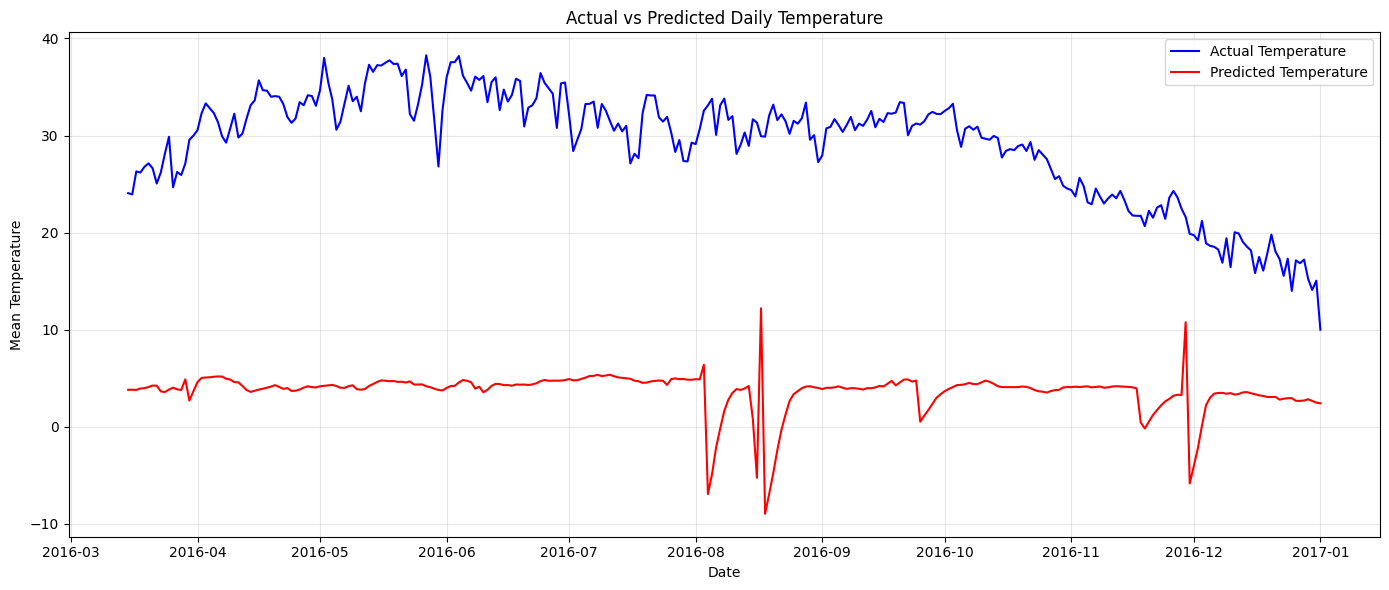

In [20]:

test_dates = df.index[target_indices[test_mask]]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_actual,
    label="Actual Temperature",
    color="blue"
)

plt.plot(
    test_dates,
    y_pred,
    label="Predicted Temperature",
    color="red"
)

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 0.1076 - mae: 0.2520 - val_loss: 0.0049 - val_mae: 0.0580
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0117 - mae: 0.0857 - val_loss: 0.0036 - val_mae: 0.0466
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0108 - mae: 0.0835 - val_loss: 0.0029 - val_mae: 0.0418
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0091 - mae: 0.0752 - val_loss: 0.0029 - val_mae: 0.0405
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0099 - mae: 0.0782 - val_loss: 0.0036 - val_mae: 0.0461
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0081 - mae: 0.0723 - val_loss: 0.0034 - val_mae: 0.0441
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0098 - mae: 0.0782 - val_loss: 0.0039 - val_mae: 0.0481
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0084 - mae: 0.0726 - val_loss: 0.0030 - val_mae: 0.0410
Epoch 9/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - lo

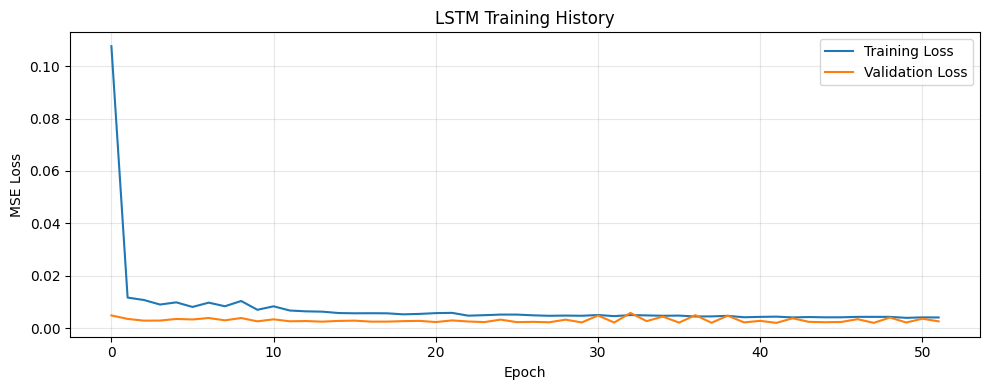

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [26]:

last_window = X_scaled[-WINDOW:]

next_day_scaled = model.predict(
    last_window.reshape(1, WINDOW, len(features)),
    verbose=0
)

next_day_temp = target_scaler.inverse_transform(
    next_day_scaled
)[0, 0]

next_date = df.index[-1] + pd.Timedelta(days=1)

print("Forecast Date:", next_date.date())
print(f"Predicted Mean Temperature: {next_day_temp:.2f}")


Forecast Date: 2017-01-02
Predicted Mean Temperature: 14.24


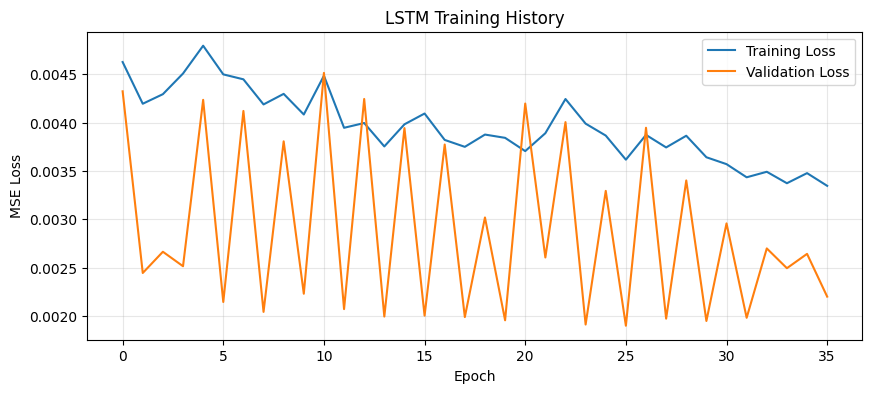

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [31]:

print("model exists:", "model" in globals())
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())

if "X_train" in globals():
    print("X_train shape:", X_train.shape)

if "y_train" in globals():
    print("y_train shape:", y_train.shape)


model exists: True
X_train exists: True
y_train exists: True
X_train shape: (1139, 30, 4)
y_train shape: (1139,)


WEATHER FORECASTING PROJECT - FINAL RESULTS

1. DATASET DETAILS
Total records: 1462
Features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
Date range: 2013-01-01 to 2017-01-01

2. LSTM MODEL PERFORMANCE
MAE  : 2.3285
RMSE : 4.1312

3. BASELINE PERFORMANCE
Baseline MAE  : 1.2592
Baseline RMSE : 1.6846
Result: LSTM did not outperform the baseline on both metrics.


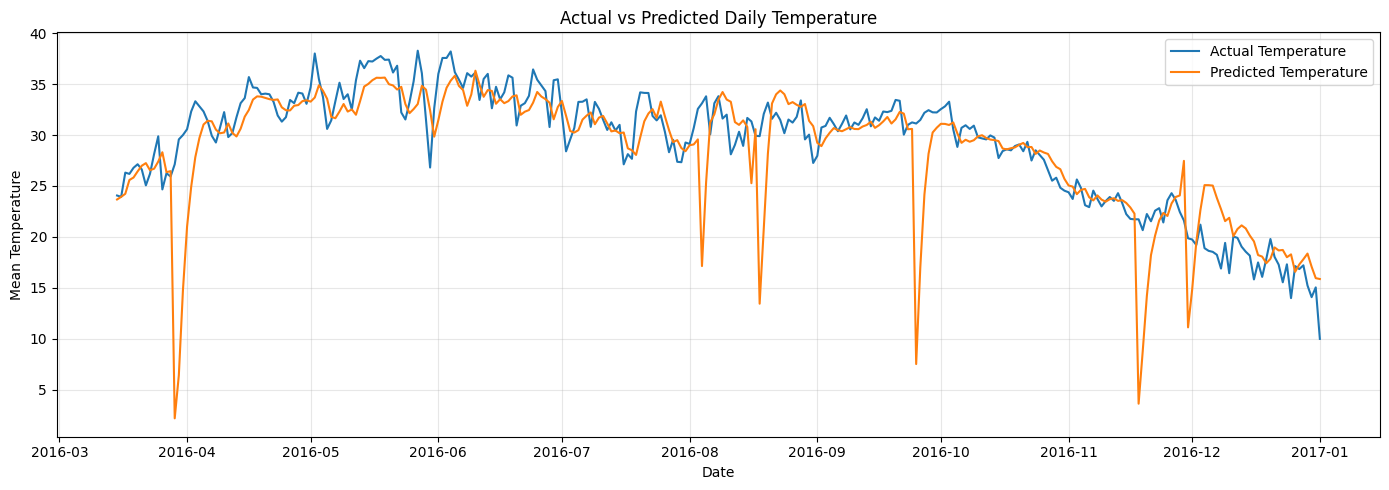

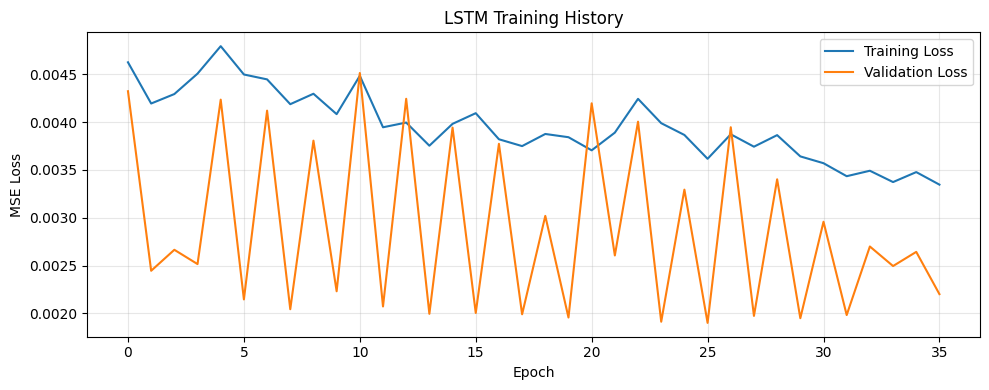


4. NEXT-DAY TEMPERATURE FORECAST
Forecast date: 2017-01-02
Predicted mean temperature: 14.06

PROJECT COMPLETED


In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Dataset details
print("=" * 50)
print("WEATHER FORECASTING PROJECT - FINAL RESULTS")
print("=" * 50)

print("\n1. DATASET DETAILS")
print("Total records:", len(df))
print("Features:", features)
print("Date range:", df.index.min().date(), "to", df.index.max().date())

# 2. LSTM predictions
pred_scaled = model.predict(X_test, verbose=0)

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred = target_scaler.inverse_transform(
    pred_scaled
).ravel()

# 3. Evaluation metrics
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("\n2. LSTM MODEL PERFORMANCE")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

# 4. Baseline comparison
baseline_scaled = X_test[:, -1, features.index(target)]

baseline_pred = target_scaler.inverse_transform(
    baseline_scaled.reshape(-1, 1)
).ravel()

baseline_mae = mean_absolute_error(y_actual, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_actual, baseline_pred)
)

print("\n3. BASELINE PERFORMANCE")
print(f"Baseline MAE  : {baseline_mae:.4f}")
print(f"Baseline RMSE : {baseline_rmse:.4f}")

if mae < baseline_mae and rmse < baseline_rmse:
    print("Result: LSTM outperformed the baseline on both metrics.")
else:
    print("Result: LSTM did not outperform the baseline on both metrics.")

# 5. Actual vs Predicted graph
test_dates = df.index[target_indices[test_mask]]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_actual, label="Actual Temperature")
plt.plot(test_dates, y_pred, label="Predicted Temperature")
plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Training history graph
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Next-day forecast
last_window = X_scaled[-WINDOW:]

next_day_scaled = model.predict(
    last_window.reshape(1, WINDOW, len(features)),
    verbose=0
)

next_day_temp = target_scaler.inverse_transform(
    next_day_scaled
)[0, 0]

next_date = df.index[-1] + pd.Timedelta(days=1)

print("\n4. NEXT-DAY TEMPERATURE FORECAST")
print("Forecast date:", next_date.date())
print(f"Predicted mean temperature: {next_day_temp:.2f}")

print("\nPROJECT COMPLETED")
